In [144]:
import numpy as np
import pandas as pd
from nltk.classify import NaiveBayesClassifier
from nltk.corpus import subjectivity
from nltk.sentiment import SentimentAnalyzer
from nltk.sentiment.util import *

import numpy as np 
import pandas as pd 
#pd.set_option('display.max_colwidth', -1)
from time import time
import re
import string
import os
from pprint import pprint
import collections

import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style="darkgrid")
sns.set(font_scale=1.3)

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.metrics import classification_report

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
#from sklearn.externals import joblib
import joblib as jb

#import gensim

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize

import warnings
warnings.filterwarnings('ignore')

np.random.seed(37)

# import stata_setup
# stata_setup.config('C:/Users/Farid Srouji/Stata15/', 'mp')
# import sys
# sys.path.append("C:/Users/Farid Srouji/Stata15/utilities")
# from pystata import config
# config.init()

In [145]:
# Reading the saved data pickle file
df  = pd.DataFrame()
df = pd.read_pickle('/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/data/pkl/pickled_filtered_lead_para_sp500_clean.pkl', compression=None)
df_sentiment=pd.read_pickle('/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/data/pkl/sentiment.pkl', compression=None)
df_vix=pd.read_csv('/Users/Farid Srouji/Documents/Research/master/globaldata/vix.csv')

In [146]:
df_vix.index = df.index

In [147]:
 pd.to_numeric(df_vix["Open"])

2019-09-25    17.049999
2019-09-26    16.230000
2019-09-27    15.770000
2019-09-30    17.230000
2019-10-01    16.020000
                ...    
2021-07-12    16.850000
2021-07-13    16.389999
2021-07-14    17.340000
2021-07-15    16.700001
2021-07-16    16.799999
Name: Open, Length: 456, dtype: float64

In [148]:
df = df.join(df_sentiment)
df = df.join(df_vix)
df["vix"] = df["adj close"]
vix_yesterday = df["vix"].shift(periods=1)
df["vix_ln_return"]=np.log(df["vix"]/vix_yesterday)
df['sentiment'] = df[["sentiment"]].apply(pd.to_numeric)
df["sentiment_ewm"]=df["sentiment"].ewm(10).mean()
df["date"]=df.index
df_part1 = df.loc['2019-09-25':'2020-02-14']
df_part2 = df.loc['2020-02-15':'2020-05-31']
df_part3 = df.loc['2020-06-01':'2021-07-15']

In [149]:
df1_part3 = df_part3
idx = pd.date_range('2020-06-01', '2021-07-15')
df1_part3.index = pd.DatetimeIndex(df1_part3.index)

In [150]:
import datetime as dt
from datetime import date
import calendar
my_date = date.today()
calendar.day_name[my_date.weekday()]  #'Wednesday'

# Prepare data
df_part3['year'] = [d.year for d in df_part3.index]
df_part3['month'] = [d.strftime('%b') for d in df_part3.index]
df_part3['day'] = [d for d in df_part3.index.day_name()]
years = df_part3['year'].unique()
df_part3['month-year'] = [d.strftime('%b') + str(d.year) for d in df_part3.index]

In [151]:
df

,close,adj close,articles,compound,neg,neu,pos,sentiment,sentiment_complementary,Date,Open,High,Low,Close,Adj Close,Volume,vix,vix_ln_return,sentiment_ewm,date
2019-09-25,15.960000,15.960000,FDA Approves Abbott's Low Dose Recharge-Free S...,1.0,0.015,0.879,0.106,87.603306,12.396694,2019-09-25,17.049999,18.450001,15.690000,15.960000,15.960000,0,15.960000,NaN,87.603306,2019-09-25
2019-09-26,16.070000,16.070000,"FDA Approves Abbott's ""Low Dose,"" Recharge-Fre...",1.0,0.022,0.859,0.118,84.285714,15.714286,2019-09-26,16.230000,17.090000,15.350000,16.070000,16.070000,0,16.070000,0.006869,85.865520,2019-09-26
2019-09-27,17.219999,17.219999,New Data Demonstrate Strong Outcomes for Abbot...,0.9998,0.033,0.862,0.105,76.086957,23.913043,2019-09-27,15.770000,18.690001,15.150000,17.219999,17.219999,0,17.219999,0.069117,82.290879,2019-09-27
2019-09-30,16.240000,16.240000,"ParTech, Inc. completed the acquisition of ass...",1.0,0.024,0.849,0.127,84.105960,15.894040,2019-09-30,17.230000,17.350000,16.200001,16.240000,16.240000,0,16.240000,-0.058594,82.811429,2019-09-30
2019-10-01,18.559999,18.559999,"Accenture plc Presents at All Day DevOps, Nov-...",0.9999,0.021,0.901,0.078,78.787879,21.212121,2019-10-01,16.020000,18.620001,15.790000,18.559999,18.559999,0,18.559999,0.133531,81.846518,2019-10-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2021-07-12,16.170000,16.170000,3M Oral Care Introduces Next-Generation Clear ...,0.9999,0.013,0.848,0.138,91.390728,8.609272,2021-07-12,16.850000,17.520000,16.139999,16.170000,16.170000,0,16.170000,-0.000618,88.107165,2021-07-12
2021-07-13,17.120001,17.120001,3M Announces Upcoming Investor Event. ST. PAUL...,1.0,0.011,0.843,0.146,92.993631,7.006369,2021-07-13,16.389999,17.230000,15.940000,17.120001,17.120001,0,17.120001,0.057090,88.551389,2021-07-13
2021-07-14,16.330000,16.330000,Cybersecurity Executive Rick Driggers Joins Ac...,0.9999,0.01,0.874,0.116,92.063492,7.936508,2021-07-14,17.340000,17.510000,15.950000,16.330000,16.330000,0,16.330000,-0.047244,88.870672,2021-07-14
2021-07-15,17.010000,17.010000,Air Products Declares Quarterly Dividend. LEHI...,1.0,0.016,0.817,0.166,91.208791,8.791209,2021-07-15,16.700001,18.090000,16.559999,17.010000,17.010000,0,17.010000,0.040797,89.083228,2021-07-15


# VIX 2010 - 2021

In [152]:
# Import Data
df_vix_2010_2021=pd.read_csv('/Users/Farid Srouji/Documents/Research/master/globaldata/vix_2010_2021.csv')
df_options=pd.read_csv('/Users/Farid Srouji/Documents/Research/master/globaldata/vix_2010_2021.csv')
df_vix_2010_2021['Date']= pd.to_datetime(df_vix_2010_2021['Date'])
df_vix_2010_2021.index= df_vix_2010_2021['Date']
print("df_vix_2010_2021['Date']="+str(type(df_vix_2010_2021['Date'])))
print("df_part3['Date']="+str(type(df_part3['date'])))

df_vix_2010_2021["vix"] = df_vix_2010_2021["Adj Close"]#.apply(np.int)
df_vix_2010_2021["vix_ln_return"]=np.log(df_vix_2010_2021["vix"]/df_vix_2010_2021["vix"].shift(1))

import datetime as dt
from datetime import date
import calendar
my_date = date.today()
calendar.day_name[my_date.weekday()] 

df_vix_2010_2021['year'] = [d.year for d in df_vix_2010_2021.Date]
df_vix_2010_2021['month'] = [d.strftime('%b') for d in df_vix_2010_2021.Date]
df_vix_2010_2021['day'] = [d for d in df_vix_2010_2021.index.day_name()]
years = df_vix_2010_2021['year'].unique()
df_vix_2010_2021['month-year'] = [d.strftime('%b') + str(d.year) for d in df_vix_2010_2021.Date]

df_vix_2010_2021['Date']=<class 'pandas.core.series.Series'>
df_part3['Date']=<class 'pandas.core.series.Series'>


# S&P500

In [153]:
import pandas as pd
#if you get an error after executing the code, try adding below:
pd.core.common.is_list_like = pd.api.types.is_list_like

import pandas_datareader.data as web
import datetime

start = datetime.datetime(2019, 9, 25)
end = datetime.datetime(2021, 7, 15)
SP500  = pd.DataFrame()

SP500 = web.DataReader(['sp500'], 'fred', start, end)

In [154]:
SP500.index

DatetimeIndex(['2019-09-25', '2019-09-26', '2019-09-27', '2019-09-30',
               '2019-10-01', '2019-10-02', '2019-10-03', '2019-10-04',
               '2019-10-07', '2019-10-08',
               ...
               '2021-07-02', '2021-07-05', '2021-07-06', '2021-07-07',
               '2021-07-08', '2021-07-09', '2021-07-12', '2021-07-13',
               '2021-07-14', '2021-07-15'],
              dtype='datetime64[ns]', name='DATE', length=472, freq=None)

In [155]:
train_start_date = '2020-06-01'
train_end_date = '2021-05-31'
test_start_date = '2021-06-01'
test_end_date = '2021-07-15'

train = df_part3.loc[train_start_date : train_end_date]
test = df_part3.loc[test_start_date:test_end_date]

In [156]:
sentiment_score_list = []
for date, row in train.T.iteritems():
    #sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    sentiment_score = np.asarray([df_part3.loc[date, 'neg'],df_part3.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_train = np.asarray(sentiment_score_list)

In [157]:
sentiment_score_list = []
for date, row in test.T.iteritems():
    #sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    sentiment_score = np.asarray([df_part3.loc[date, 'neg'],df_part3.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_test = np.asarray(sentiment_score_list)

In [158]:
y_train = pd.DataFrame(train['vix'])
y_test = pd.DataFrame(test['vix'])

In [159]:
from treeinterpreter import treeinterpreter as ti
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import classification_report,confusion_matrix

rf = RandomForestRegressor()
y_train = np.nan_to_num(y_train)
numpy_df_train = np.nan_to_num(numpy_df_train)
rf.fit(numpy_df_train, y_train)

RandomForestRegressor()

In [160]:
prediction, bias, contributions = ti.predict(rf, numpy_df_test)

In [161]:
idx = y_test.index
predictions_df = pd.DataFrame(data=prediction[0:], index = idx, columns=['predicted_vix'] )

In [162]:
train

,close,adj close,articles,compound,neg,neu,pos,sentiment,sentiment_complementary,Date,...,Adj Close,Volume,vix,vix_ln_return,sentiment_ewm,date,year,month,day,month-year
2020-06-01,28.230000,28.230000,Abbvie Submits Regulatory Applications To FDA ...,0.9994,0.018,0.865,0.117,86.666667,13.333333,2020-06-01,...,28.230000,0,28.230000,0.025836,78.231366,2020-06-01,2020,Jun,Monday,Jun2020
2020-06-02,26.840000,26.840000,Bigfoot Biomedical® Closes Series C Financing ...,0.999,0.024,0.861,0.114,82.608696,17.391304,2020-06-02,...,26.840000,0,26.840000,-0.050492,78.629305,2020-06-02,2020,Jun,Tuesday,Jun2020
2020-06-03,25.660000,25.660000,3M Appoints Monish Patolawala As New Chief Fin...,0.9996,0.021,0.843,0.136,86.624204,13.375796,2020-06-03,...,25.660000,0,25.660000,-0.044960,79.356114,2020-06-03,2020,Jun,Wednesday,Jun2020
2020-06-04,25.809999,25.809999,Abbvie Says Rinvoq's Safety Profile Was Consis...,0.9997,0.022,0.847,0.131,85.620915,14.379085,2020-06-04,...,25.809999,0,25.809999,0.005829,79.925642,2020-06-04,2020,Jun,Thursday,Jun2020
2020-06-05,24.520000,24.520000,"Abbvie, Harbour Biomed, Utrecht University And...",0.7187,0.1,0.798,0.101,50.248756,49.751244,2020-06-05,...,24.520000,0,24.520000,-0.051273,77.227742,2020-06-05,2020,Jun,Friday,Jun2020
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2021-05-24,18.400000,18.400000,3M introduces 3M™ Environmental Scrub Sampler ...,1.0,0.024,0.85,0.126,84.000000,16.000000,2021-05-24,...,18.400000,0,18.400000,-0.090854,86.336047,2021-05-24,2021,May,Monday,May2021
2021-05-25,18.840000,18.840000,AbbVie Receives European Commission Approval o...,1.0,0.01,0.83,0.16,94.117647,5.882353,2021-05-25,...,18.840000,0,18.840000,0.023632,87.043467,2021-05-25,2021,May,Tuesday,May2021
2021-05-26,17.360001,17.360001,Accenture Acquires Industrie&Co to Help Austra...,0.9999,0.014,0.863,0.123,89.781022,10.218978,2021-05-26,...,17.360001,0,17.360001,-0.081814,87.292336,2021-05-26,2021,May,Wednesday,May2021
2021-05-27,16.740000,16.740000,AMD EPYC™ Processors Accelerate High Performan...,1.0,0.008,0.824,0.169,95.480226,4.519774,2021-05-27,...,16.740000,0,16.740000,-0.036368,88.036692,2021-05-27,2021,May,Thursday,May2021


i=0
col=sentiment
i=1
col=Open
i=2
col=High
i=3
col=Low


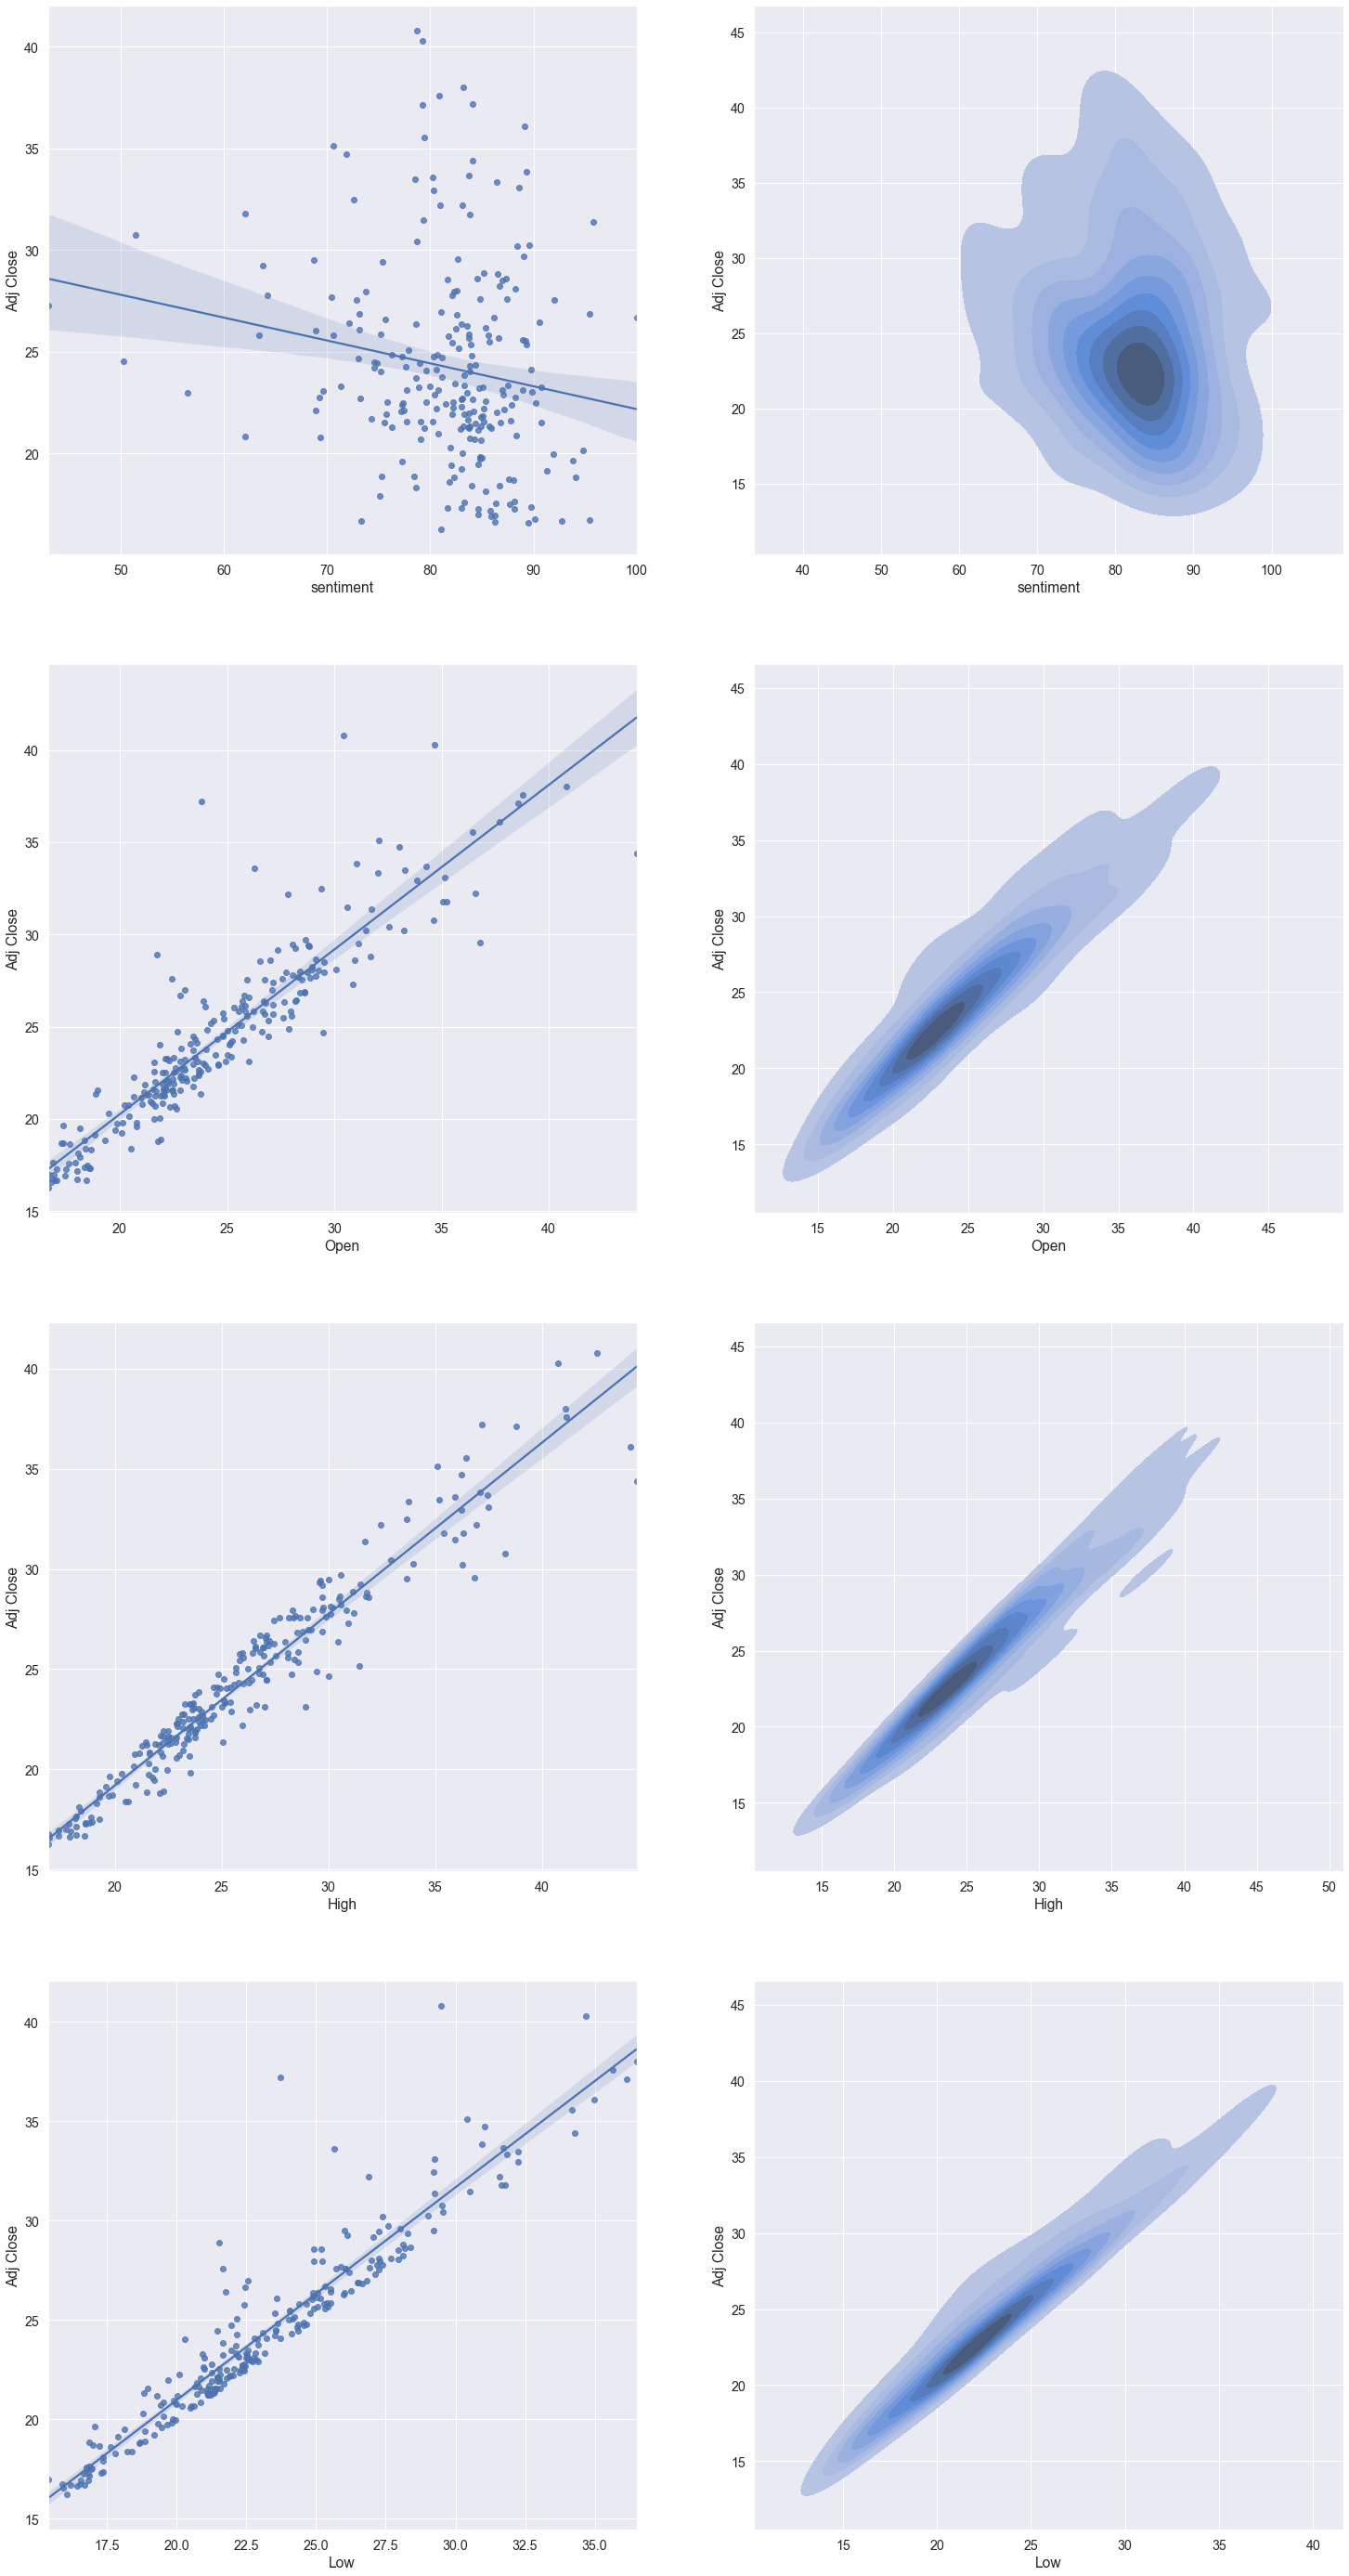

In [163]:
# Columns to plot 
plot_columns = ["sentiment", "Open","High", "Low"]
fig, axes = plt.subplots(4,2,figsize=(25,50))
for i,col in enumerate(plot_columns):
    print("i="+str(i))
    print("col="+str(col))

    sns.regplot(col,'Adj Close',data=train, ax=axes[i,0]) # regression plot
    sns.kdeplot(train[col],train['Adj Close'],shade=True, ax=axes[i,1]) # kernel density estimate plot

In [164]:
df_part3

,close,adj close,articles,compound,neg,neu,pos,sentiment,sentiment_complementary,Date,...,Adj Close,Volume,vix,vix_ln_return,sentiment_ewm,date,year,month,day,month-year
2020-06-01,28.230000,28.230000,Abbvie Submits Regulatory Applications To FDA ...,0.9994,0.018,0.865,0.117,86.666667,13.333333,2020-06-01,...,28.230000,0,28.230000,0.025836,78.231366,2020-06-01,2020,Jun,Monday,Jun2020
2020-06-02,26.840000,26.840000,Bigfoot Biomedical® Closes Series C Financing ...,0.999,0.024,0.861,0.114,82.608696,17.391304,2020-06-02,...,26.840000,0,26.840000,-0.050492,78.629305,2020-06-02,2020,Jun,Tuesday,Jun2020
2020-06-03,25.660000,25.660000,3M Appoints Monish Patolawala As New Chief Fin...,0.9996,0.021,0.843,0.136,86.624204,13.375796,2020-06-03,...,25.660000,0,25.660000,-0.044960,79.356114,2020-06-03,2020,Jun,Wednesday,Jun2020
2020-06-04,25.809999,25.809999,Abbvie Says Rinvoq's Safety Profile Was Consis...,0.9997,0.022,0.847,0.131,85.620915,14.379085,2020-06-04,...,25.809999,0,25.809999,0.005829,79.925642,2020-06-04,2020,Jun,Thursday,Jun2020
2020-06-05,24.520000,24.520000,"Abbvie, Harbour Biomed, Utrecht University And...",0.7187,0.1,0.798,0.101,50.248756,49.751244,2020-06-05,...,24.520000,0,24.520000,-0.051273,77.227742,2020-06-05,2020,Jun,Friday,Jun2020
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2021-07-09,16.180000,16.180000,Accenture Completes Acquisition of Linkbynet f...,0.9992,0.021,0.862,0.118,84.892086,15.107914,2021-07-09,...,16.180000,0,16.180000,-0.160663,87.778809,2021-07-09,2021,Jul,Friday,Jul2021
2021-07-12,16.170000,16.170000,3M Oral Care Introduces Next-Generation Clear ...,0.9999,0.013,0.848,0.138,91.390728,8.609272,2021-07-12,...,16.170000,0,16.170000,-0.000618,88.107165,2021-07-12,2021,Jul,Monday,Jul2021
2021-07-13,17.120001,17.120001,3M Announces Upcoming Investor Event. ST. PAUL...,1.0,0.011,0.843,0.146,92.993631,7.006369,2021-07-13,...,17.120001,0,17.120001,0.057090,88.551389,2021-07-13,2021,Jul,Tuesday,Jul2021
2021-07-14,16.330000,16.330000,Cybersecurity Executive Rick Driggers Joins Ac...,0.9999,0.01,0.874,0.116,92.063492,7.936508,2021-07-14,...,16.330000,0,16.330000,-0.047244,88.870672,2021-07-14,2021,Jul,Wednesday,Jul2021


In [165]:
df_part3["year"]

2020-06-01    2020
2020-06-02    2020
2020-06-03    2020
2020-06-04    2020
2020-06-05    2020
              ... 
2021-07-09    2021
2021-07-12    2021
2021-07-13    2021
2021-07-14    2021
2021-07-15    2021
Name: year, Length: 284, dtype: int64

In [170]:
import plotly.offline as py
import plotly.graph_objs as go
from plotly.offline import iplot

# 2017 onwards
last_year = df_part3.loc[df_part3['year'] == 2021]
last_month = last_year.loc[last_year['month'] == "Jun"]
g = last_month.groupby(["Date"])
# g = df_part3.groupby(["Date"])

monthly_averages = g.aggregate({"Open": np.mean, "High": np.mean, "Low": np.mean, "Close":np.mean})
monthly_averages.reset_index(level=0, inplace=True)

monthly_averages.dtypes


trace = go.Candlestick(x=monthly_averages['Date'],
                       open=monthly_averages['Open'].values.tolist(),
                       high=monthly_averages['High'].values.tolist(),
                       low=monthly_averages['Low'].values.tolist(),
                       close=monthly_averages['Close'].values.tolist(),
                      increasing=dict(line=dict(color= '#58FA58')),
                decreasing=dict(line=dict(color= '#FA5858')))


layout = {
    'title': 'VIX <br> <i>A closer look to the upward trend </i>',
    'xaxis': {'title': 'Date',
             'rangeslider': {'visible': False}},
    'yaxis': {'title': 'Stock Price (USD$)'}
}


data = [trace]

fig = go.Figure(data=data, layout=layout)
iplot(fig, filename='simple_ohlc')

In [174]:
train

,close,adj close,articles,compound,neg,neu,pos,sentiment,sentiment_complementary,Date,...,Adj Close,Volume,vix,vix_ln_return,sentiment_ewm,date,year,month,day,month-year
2020-06-01,28.230000,28.230000,Abbvie Submits Regulatory Applications To FDA ...,0.9994,0.018,0.865,0.117,86.666667,13.333333,2020-06-01,...,28.230000,0,28.230000,0.025836,78.231366,2020-06-01,2020,Jun,Monday,Jun2020
2020-06-02,26.840000,26.840000,Bigfoot Biomedical® Closes Series C Financing ...,0.999,0.024,0.861,0.114,82.608696,17.391304,2020-06-02,...,26.840000,0,26.840000,-0.050492,78.629305,2020-06-02,2020,Jun,Tuesday,Jun2020
2020-06-03,25.660000,25.660000,3M Appoints Monish Patolawala As New Chief Fin...,0.9996,0.021,0.843,0.136,86.624204,13.375796,2020-06-03,...,25.660000,0,25.660000,-0.044960,79.356114,2020-06-03,2020,Jun,Wednesday,Jun2020
2020-06-04,25.809999,25.809999,Abbvie Says Rinvoq's Safety Profile Was Consis...,0.9997,0.022,0.847,0.131,85.620915,14.379085,2020-06-04,...,25.809999,0,25.809999,0.005829,79.925642,2020-06-04,2020,Jun,Thursday,Jun2020
2020-06-05,24.520000,24.520000,"Abbvie, Harbour Biomed, Utrecht University And...",0.7187,0.1,0.798,0.101,50.248756,49.751244,2020-06-05,...,24.520000,0,24.520000,-0.051273,77.227742,2020-06-05,2020,Jun,Friday,Jun2020
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2021-05-24,18.400000,18.400000,3M introduces 3M™ Environmental Scrub Sampler ...,1.0,0.024,0.85,0.126,84.000000,16.000000,2021-05-24,...,18.400000,0,18.400000,-0.090854,86.336047,2021-05-24,2021,May,Monday,May2021
2021-05-25,18.840000,18.840000,AbbVie Receives European Commission Approval o...,1.0,0.01,0.83,0.16,94.117647,5.882353,2021-05-25,...,18.840000,0,18.840000,0.023632,87.043467,2021-05-25,2021,May,Tuesday,May2021
2021-05-26,17.360001,17.360001,Accenture Acquires Industrie&Co to Help Austra...,0.9999,0.014,0.863,0.123,89.781022,10.218978,2021-05-26,...,17.360001,0,17.360001,-0.081814,87.292336,2021-05-26,2021,May,Wednesday,May2021
2021-05-27,16.740000,16.740000,AMD EPYC™ Processors Accelerate High Performan...,1.0,0.008,0.824,0.169,95.480226,4.519774,2021-05-27,...,16.740000,0,16.740000,-0.036368,88.036692,2021-05-27,2021,May,Thursday,May2021


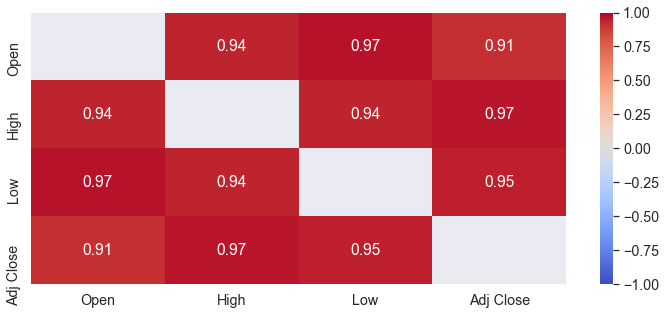

In [175]:
# Correlation matrix
plot_columns = ["Open","High", "Low", "Adj Close", ]

corr = train[plot_columns].corr()

mask = np.zeros_like(corr)
for i in range(mask.shape[0]):
    mask[i,i]=True
plt.figure(figsize=(12,5))
sns.heatmap(corr,annot=True,mask=mask,cmap='coolwarm',vmin=-1,vmax=1)
plt.show()

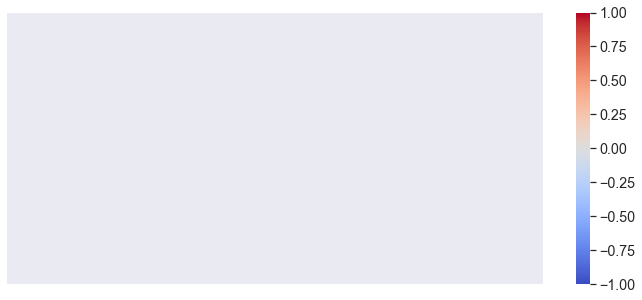

In [177]:
# Correlation matrix
plot_columns = ["neg", "neu","pos"]

corr = train[plot_columns].corr()

mask = np.zeros_like(corr)
for i in range(mask.shape[0]):
    mask[i,i]=True
plt.figure(figsize=(12,5))
sns.heatmap(corr,annot=True,mask=mask,cmap='coolwarm',vmin=-1,vmax=1)
plt.show()